## Busniss Problem
A global e-commerece company operating across multiple regions manages end to end order fulfillment,including shipping and delivery,for products like sporting goods.The company is facing inconsistent delivery performance,where acrual shipping times often deviate from scheduled timelines,leading to late deliveries and unpredictable order profiability.

## Desired Outcomes:
The goal is to analyze delivery operations,identify bottlenecks and build a predictive system to reduce delays,optimize shipping decisions and improve overall profitablity and efficiency.  
  


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')

In [20]:
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.facecolor'] = '#FFFFFF'
plt.rcParams['axes.facecolor'] = '#F8FAFC'
plt.rcParams['axes.titlecolor'] = '#12304A'
plt.rcParams['axes.labelcolor'] = '#1E293B'
plt.rcParams['grid.color'] = '#E2E8F0'
plt.rcParams['font.family'] = 'DejaVu Sans'
# Professional Color Theme
primary_color = '#1F4E78'      # Corporate Blue
secondary_color = '#5B9BD5'    # Soft Blue
accent_color = '#00A6A6'       # Professional Teal
background_color = '#F4F7FA'   # Light Grey
text_color = '#263238'         # Dark Grey

In [21]:
df=pd.read_csv('C:/Users/khush/OneDrive/Desktop/Data analysis/Dataset/DataCoSupplyChainDataset.csv',encoding='latin-1')
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [22]:
df

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class


In [23]:
print('rows,cols:',df.shape)
print('\ncolumns:')
print(df.columns.tolist())
print('\nNum duplicates:',df.duplicated().sum())
print('\nMissing values(top 20):')
print(df.isna().sum().sort_values(ascending=False).head(20))

rows,cols: (180519, 53)

columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product

In [25]:
import pandas as pd

df = pd.read_csv(
    'C:/Users/khush/OneDrive/Desktop/Data analysis/Dataset/DataCoSupplyChainDataset.csv',
    encoding='latin1'
)

print("Original shape:", df.shape)

Original shape: (180519, 53)


In [26]:
print(df.columns.tolist())

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrde

In [27]:
import pandas as pd

df = pd.read_csv(
    'C:/Users/khush/OneDrive/Desktop/Data analysis/Dataset/DataCoSupplyChainDataset.csv',
    encoding='latin1'
)

print(df['Product Status'].value_counts())

Product Status
0    180519
Name: count, dtype: int64


In [28]:

# Select exactly 20 useful columns
columns_to_keep = [
    'Type',
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Sales per customer',
    'Delivery Status',
    'Late_delivery_risk',
    'Category Name',
    'Customer Country',
    'Customer Segment',
    'Department Name',
    'Order Item Profit Ratio',
    'Sales',
    'Order Item Total',
    'Order Profit Per Order',
    'Order Region',
    'Order Status',
    'Product Name',
    'Shipping Mode',
    'order date (DateOrders)'
]

# Check whether columns exist
missing_columns = [col for col in columns_to_keep if col not in df.columns]

if missing_columns:
    print("Columns not found:", missing_columns)
else:
    # Keep only the selected columns
    df = df[columns_to_keep].copy()

    # Remove canceled orders
    df = df[df['Delivery Status'] != 'Shipping canceled'].copy()

    # Convert order date
    df['order date (DateOrders)'] = pd.to_datetime(
        df['order date (DateOrders)'],
        errors='coerce'
    )

    # Display results
    print("Rows and columns:", df.shape)
    print("\nTotal columns:", len(df.columns))
    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nMissing values (top 5):")
    print(df.isna().sum().sort_values(ascending=False).head(5))

    display(df.head())

Rows and columns: (172765, 20)

Total columns: 20

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Name', 'Customer Country', 'Customer Segment', 'Department Name', 'Order Item Profit Ratio', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order Status', 'Product Name', 'Shipping Mode', 'order date (DateOrders)']

Missing values (top 5):
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
dtype: int64


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,Order Item Profit Ratio,Sales,Order Item Total,Order Profit Per Order,Order Region,Order Status,Product Name,Shipping Mode,order date (DateOrders)
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,0.29,327.75,314.640015,91.250000,Southeast Asia,COMPLETE,Smart watch,Standard Class,2018-01-31 22:56:00
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,-0.80,327.75,311.359985,-249.089996,South Asia,PENDING,Smart watch,Standard Class,2018-01-13 12:27:00
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,-0.80,327.75,309.720001,-247.779999,South Asia,CLOSED,Smart watch,Standard Class,2018-01-13 12:06:00
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,0.08,327.75,304.809998,22.860001,Oceania,COMPLETE,Smart watch,Standard Class,2018-01-13 11:45:00
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,0.45,327.75,298.250000,134.210007,Oceania,PENDING_PAYMENT,Smart watch,Standard Class,2018-01-13 11:24:00


In [29]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,Order Item Profit Ratio,Sales,Order Item Total,Order Profit Per Order,Order Region,Order Status,Product Name,Shipping Mode,order date (DateOrders)
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,0.29,327.75,314.640015,91.250000,Southeast Asia,COMPLETE,Smart watch,Standard Class,2018-01-31 22:56:00
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,-0.80,327.75,311.359985,-249.089996,South Asia,PENDING,Smart watch,Standard Class,2018-01-13 12:27:00
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,-0.80,327.75,309.720001,-247.779999,South Asia,CLOSED,Smart watch,Standard Class,2018-01-13 12:06:00
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,0.08,327.75,304.809998,22.860001,Oceania,COMPLETE,Smart watch,Standard Class,2018-01-13 11:45:00
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,0.45,327.75,298.250000,134.210007,Oceania,PENDING_PAYMENT,Smart watch,Standard Class,2018-01-13 11:24:00


In [30]:
for col in df.columns:
    if df[col].nunique()<10:
        print(f'\n{col},value counts:')
        print(df[col].value_counts())


Type,value counts:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real),value counts:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Days for shipment (scheduled),value counts:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Delivery Status,value counts:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Late_delivery_risk,value counts:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

Customer Country,value counts:
Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

Customer Segment,value counts:
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

Order Status,value counts:
Order Status
COMPLETE  

In [31]:
print(df.columns.tolist())


['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Name', 'Customer Country', 'Customer Segment', 'Department Name', 'Order Item Profit Ratio', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order Status', 'Product Name', 'Shipping Mode', 'order date (DateOrders)']


In [32]:
print([col for col in df.columns if 'date' in col.lower()])

['order date (DateOrders)']


In [33]:
import pandas as pd

df = pd.read_csv(
    'C:/Users/khush/OneDrive/Desktop/Data analysis/Dataset/DataCoSupplyChainDataset.csv',
    encoding='latin1'
)


# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert dates to datetime
df['shipping date (DateOrders)'] = pd.to_datetime(
    df['shipping date (DateOrders)'], errors='coerce'
)

df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'], errors='coerce'
)

# Calculate processing time and delay
df['Order Processing Time'] = (
    df['shipping date (DateOrders)'] -df['order date (DateOrders)']
).dt.days

df['Delay'] = (
    df['Order Processing Time'] -
    df['Days for shipment (scheduled)']
)

df['Is_Delayed'] = df['Delay'] > 0

# Extract date information
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.day_name()
df['order_hour'] = df['order date (DateOrders)'].dt.hour

df.describe()

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Product Card Id,Product Category Id,Product Description,Product Price,Product Status,shipping date (DateOrders),Order Processing Time,Delay,order_month,order_hour
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,0.0,180519.000000,180519.0,180519,180519.000000,180519.000000,180519.000000,180519.000000
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,692.509764,31.851451,NaN,141.232550,0.0,2016-06-16 05:45:23.202433024,3.471856,0.540010,6.235449,11.483689
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,19.000000,2.000000,NaN,9.990000,0.0,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,403.000000,18.000000,NaN,50.000000,0.0,2015-09-25 06:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,627.000000,29.000000,NaN,59.990002,0.0,2016-06-15 08:32:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,1004.000000,45.000000,NaN,199.990005,0.0,2017-03-04 21:29:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,1363.000000,76.000000,NaN,1999.989990,0.0,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,336.446807,15.640064,NaN,139.732492,0.0,NaN,1.670471,1.491881,3.403571,6.923006


In [34]:
df['Is_Delayed'].value_counts()

Is_Delayed
True     98743
False    81776
Name: count, dtype: int64

In [35]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [36]:
df['Order Profit Per Order']>0

0          True
1         False
2         False
3          True
4          True
          ...  
180514     True
180515    False
180516     True
180517     True
180518     True
Name: Order Profit Per Order, Length: 180519, dtype: bool

In [37]:
# Create profitability flag

df['Profitability_Flag'] = df['Order Profit Per Order'].apply(
    lambda x: 'Profitable' if x > 0 else 'Loss'
)


df['Profitability_Flag'].value_counts()

Profitability_Flag
Profitable    145558
Loss           34961
Name: count, dtype: int64

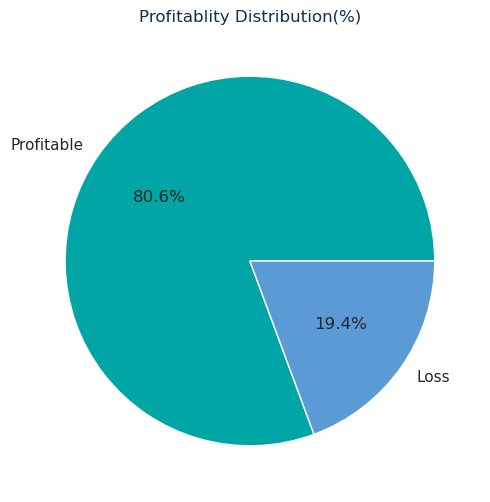

In [38]:
#visualization of profitability distribution
profit_counts=df['Profitability_Flag'].value_counts(normalize=True)*100
profit_counts.plot(kind='pie',autopct='%1.1f%%',colors=[accent_color,secondary_color])
plt.ylabel('')
plt.title('Profitablity Distribution(%)')
plt.show()

In [39]:
# Business KPI

def format_func(value):
    if value>=1e6:
        return f'{value/1e6:1f}M $'
    elif value>=1e3:
        return f'{value/1e3:1f}K $'
    else:
        return f'{value:0f} $'

delayed_df=df[df['Delay']>0]
metrics={}
metrics['Total Orders']=len(df)
metrics['Late Delivers']=len(delayed_df)
metrics['90% Delay(days)']=delayed_df['Delay'].quantile(0.90)
metrics['On time Delivery %']=(1-float(metrics['Late Delivers'])/ metrics['Total Orders'])*100
metrics['Late Delivery %']=float(metrics['Late Delivers'])/ metrics['Total Orders']*100
metrics['Total Profit']=format_func(df.loc[df['Order Profit Per Order']>0,'Order Profit Per Order'].sum())
metrics['Total Loss due to delays']=format_func(df.loc[df['Delay']>0,'Order Profit Per Order'].sum())

print('\n---Business KPIs ---\n')
for k,v in metrics.items():
    if isinstance(v,float):
        print(f"{k}:{v:2f}")
    else:
        print(f"{k}:{v}")

    


---Business KPIs ---

Total Orders:180519
Late Delivers:98743
90% Delay(days):3.000000
On time Delivery %:45.300495
Late Delivery %:54.699505
Total Profit:7.850450M $
Total Loss due to delays:2.145747M $


In [40]:
# Profitability vs Delivery Time Analysis

profit_metrics=(
    df.groupby('Delay')['Order Profit Per Order']
    .agg(
        mean_profit='mean',
        total_profit='sum',
        order_count='count'
    )
    .reset_index()
)

In [41]:
profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2,23.423528,5.074942e+05,21666
1,-1,21.516997,4.669188e+05,21700
2,0,22.044854,8.467429e+05,38410
3,1,22.225592,1.244411e+06,55990
4,2,21.246239,6.101495e+05,28718
5,3,19.941130,1.406248e+05,7052
6,4,21.561202,1.505619e+05,6983


In [42]:
delay_distribution=(
    df['Delay']
    .value_counts(normalize=True)
    .sort_index()*100
).reset_index()

In [43]:
delay_distribution

,Delay,proportion
0,-2,12.002061
1,-1,12.020895
2,0,21.277539
3,1,31.016126
4,2,15.908575
5,3,3.906514
6,4,3.868291



Profit metrics by delay day:


,Delay,mean_profit,total_profit,order_count
0,-2,23.4,507494.2,21666
1,-1,21.5,466918.8,21700
2,0,22.0,846742.9,38410
3,1,22.2,1244410.9,55990
4,2,21.2,610149.5,28718
5,3,19.9,140624.8,7052
6,4,21.6,150561.9,6983



Delay Distribution (%):


,Delay_Days,Percentage
0,-2,12.002061
1,-1,12.020895
2,0,21.277539
3,1,31.016126
4,2,15.908575
5,3,3.906514
6,4,3.868291


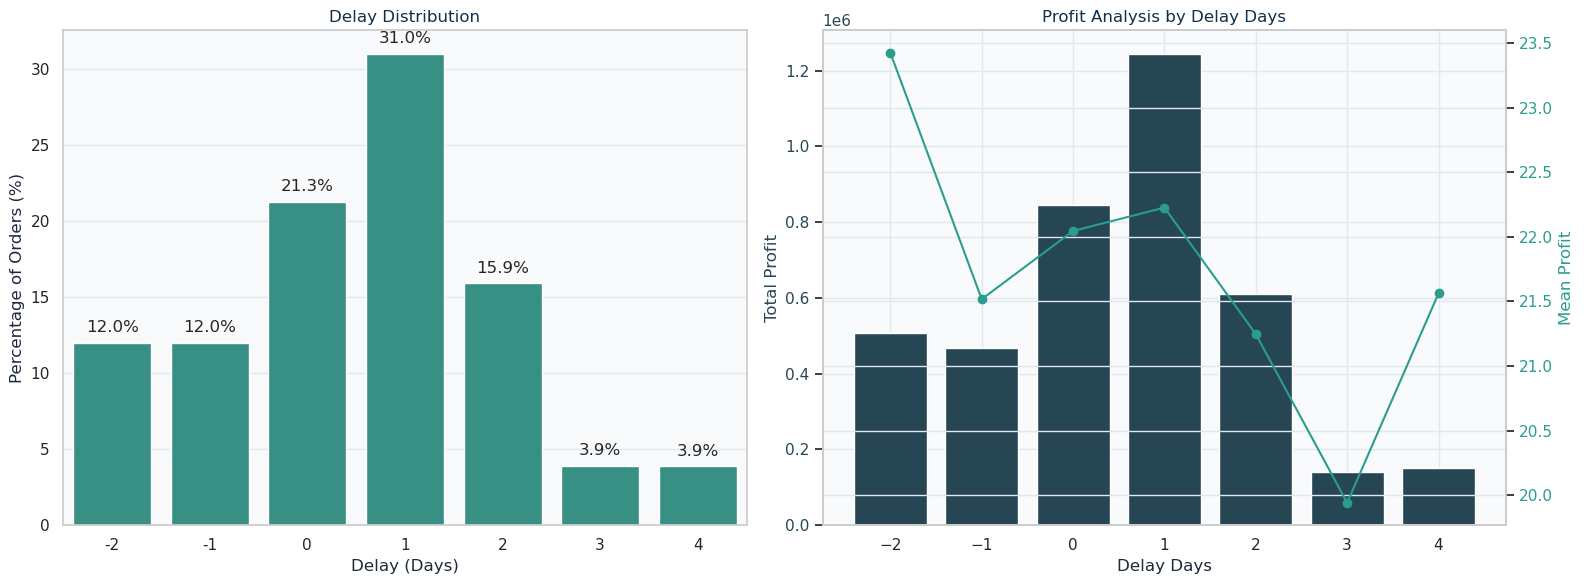

In [44]:
primary_color = '#264653'  # Professional dark blue
accent_color = '#2A9D8F'   # Professional teal


delay_distribution.columns = ['Delay_Days', 'Percentage']

print("\nProfit metrics by delay day:")
display(profit_metrics.round(1))

print("\nDelay Distribution (%):")
display(delay_distribution)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# First subplot: Delay Distribution
sns.barplot(
    x='Delay_Days',
    y='Percentage',
    data=delay_distribution,
    color=accent_color,
    ax=ax1
)

ax1.set_title('Delay Distribution')
ax1.set_xlabel('Delay (Days)')
ax1.set_ylabel('Percentage of Orders (%)')

# Percentage text on bars
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'{height:.1f}%',
        ha='center',
        va='bottom'
    )

# Second subplot: Profit Analysis by Delay Days
ax2.set_title('Profit Analysis by Delay Days')

ax2.bar(
    profit_metrics['Delay'],
    profit_metrics['total_profit'],
    color=primary_color,
    label='Total Profit'
)

ax2.set_xlabel('Delay Days')
ax2.set_ylabel('Total Profit', color=primary_color)
ax2.tick_params(axis='y', labelcolor=primary_color)

# Secondary Y-axis
ax3 = ax2.twinx()

ax3.set_ylabel('Mean Profit', color=accent_color)

ax3.plot(
    profit_metrics['Delay'],
    profit_metrics['mean_profit'],
    marker='o',
    label='Mean Profit',
    color=accent_color
)

ax3.tick_params(axis='y', labelcolor=accent_color)

plt.tight_layout()
plt.show()



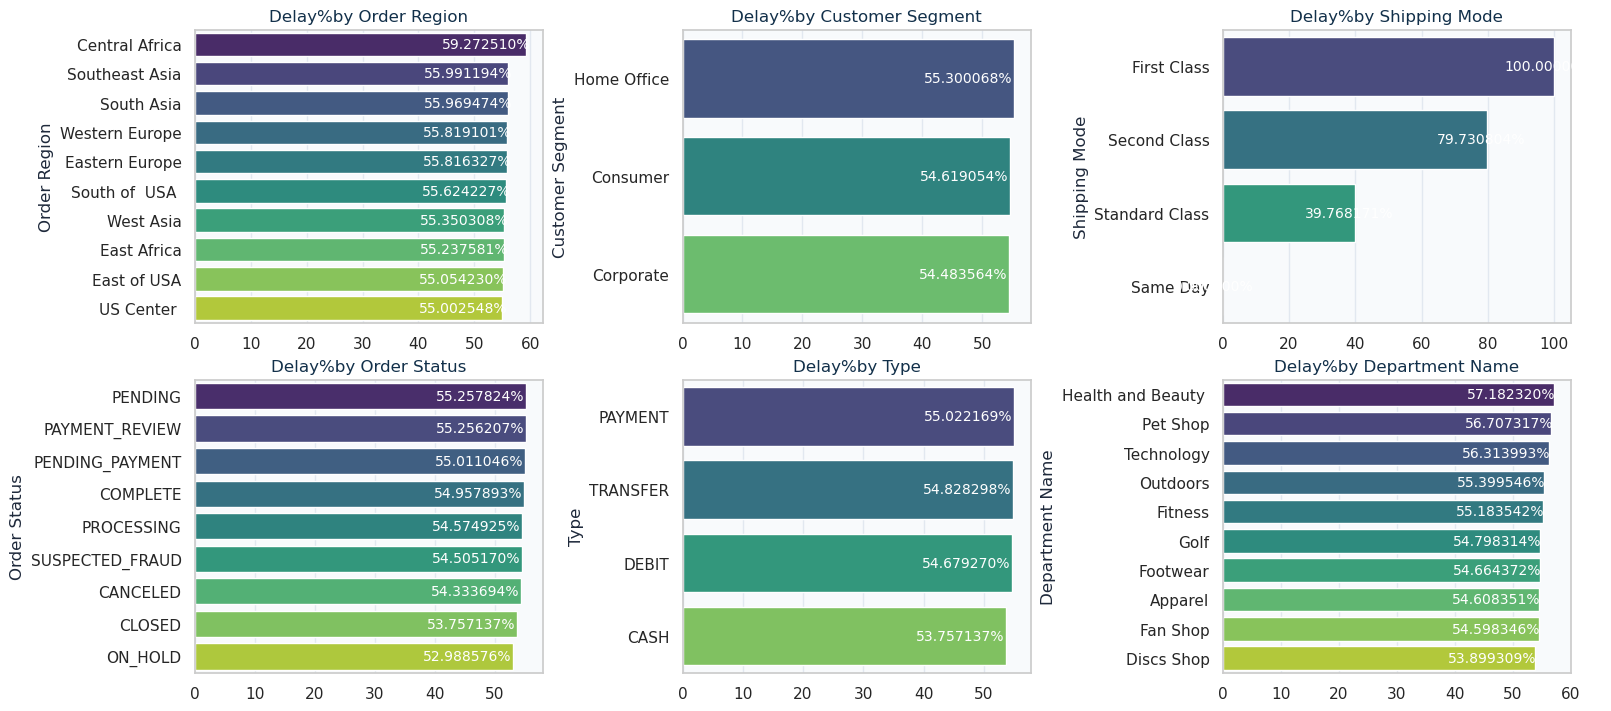

In [45]:
# Bottleneck Detection

def compute_delay_pct_by_category(category):
    cat_df=df.groupby(category).agg(
        total_orders=('Delay','count'),
        late_orders=('Is_Delayed','sum')
    ).reset_index()
    cat_df['delay_pct']=cat_df['late_orders']/cat_df['total_orders']*100
    cat_df=cat_df.sort_values('delay_pct',ascending=False).head(10)
    return cat_df

categories=['Order Region','Customer Segment','Shipping Mode','Order Status','Type','Department Name']

fig,axes=plt.subplots(2,3,figsize=(16,7),constrained_layout=True)
axes=axes.flatten()

for ax,category in zip(axes,categories):
    cat_df=compute_delay_pct_by_category(category)
    sns.barplot(
        data=cat_df,
        x='delay_pct',
        y=category,
        ax=ax,
        palette='viridis'
    )
    ax.set_title(f'Delay%by {category}')
    ax.set_xlabel('')
    ax.set_ylabel(category)
    for i,row in cat_df.reset_index().iterrows():
            ax.text(row['delay_pct']-15,i,f"{row['delay_pct']:1f}%",va='center',fontsize=10,color='white')

plt.show()

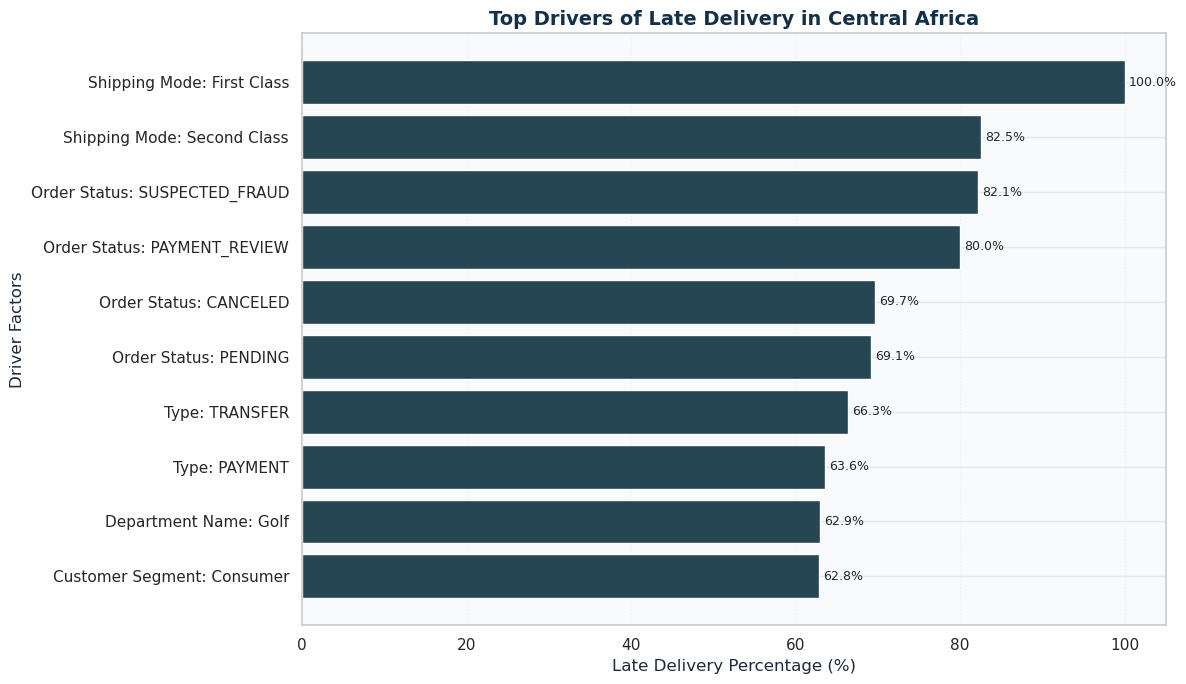

,Driver,Factor_Level,delay_pct,avg_delay,total_orders
4,Customer Segment,Customer Segment: Consumer,62.787879,0.683636,825
11,Department Name,Department Name: Golf,62.931034,0.698276,348
15,Type,Type: PAYMENT,63.583815,0.763006,346
16,Type,Type: TRANSFER,66.313559,0.667373,472
22,Order Status,Order Status: PENDING,69.148936,0.574468,188
17,Order Status,Order Status: CANCELED,69.696970,0.878788,33
21,Order Status,Order Status: PAYMENT_REVIEW,80.000000,1.200000,20
25,Order Status,Order Status: SUSPECTED_FRAUD,82.142857,1.035714,28
2,Shipping Mode,Shipping Mode: Second Class,82.491582,2.127946,297
0,Shipping Mode,Shipping Mode: First Class,100.000000,1.000000,300


In [46]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    'C:/Users/khush/OneDrive/Desktop/Data analysis/Dataset/DataCoSupplyChainDataset.csv',
    encoding='latin1'
)



# Create Delay column if it does not exist
if 'Delay' not in df.columns:
    df['Delay'] = (
        df['Days for shipping (real)']
        - df['Days for shipment (scheduled)']
    )

# Create Is_Delayed column if it does not exist
if 'Is_Delayed' not in df.columns:
    df['Is_Delayed'] = (df['Delay'] > 0).astype(int)


# Root Cause Analysis
# Top drivers of late delivery by region

def top_drivers_for_region(region):

    df_region = df[df['Order Region'] == region].copy()

    if df_region.empty:
        print(f"No data found for region: {region}")
        print("Available regions:")
        print(df['Order Region'].dropna().unique())
        return

    drivers = [
        'Shipping Mode',
        'Customer Segment',
        'Department Name',
        'Type',
        'Order Status'
    ]

    all_factors = []

    for factor in drivers:

        temp = (
            df_region.groupby(factor, dropna=False)
            .agg(
                total_orders=('Delay', 'count'),
                late_orders=('Is_Delayed', 'sum'),
                avg_delay=('Delay', 'mean')
            )
            .reset_index()
        )

        temp['delay_pct'] = (
            temp['late_orders']
            / temp['total_orders']
            * 100
        )

        temp['Driver'] = factor

        temp['Factor_Level'] = (
            factor + ': ' + temp[factor].astype(str)
        )

        all_factors.append(
            temp[
                [
                    'Driver',
                    'Factor_Level',
                    'delay_pct',
                    'avg_delay',
                    'total_orders'
                ]
            ]
        )

    # Combine all drivers
    final_df = pd.concat(all_factors, ignore_index=True)

    # Select top 10 drivers
    top_factors = (
        final_df.sort_values(
            'delay_pct',
            ascending=False
        )
        .head(10)
        .sort_values('delay_pct')
    )

    # Professional visualization
    fig, ax = plt.subplots(figsize=(12, 7))

    bars = ax.barh(
        top_factors['Factor_Level'],
        top_factors['delay_pct'],
        color=primary_color
    )

    ax.set_xlabel('Late Delivery Percentage (%)')
    ax.set_ylabel('Driver Factors')

    ax.set_title(
        f'Top Drivers of Late Delivery in {region}',
        fontsize=14,
        fontweight='bold'
    )

    ax.grid(axis='x', linestyle=':', alpha=0.4)
    ax.set_axisbelow(True)

    # Percentage labels
    for bar in bars:
        width = bar.get_width()

        ax.text(
            width + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f'{width:.1f}%',
            va='center',
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

    return top_factors


# Run analysis
top_drivers_for_region('Central Africa')



In [47]:
print(df.columns.tolist())

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrde

In [50]:
# Convert order date to datetime
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'], errors='coerce'
)

# Extract time-based columns
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.dayofweek
df['order_hour'] = df['order date (DateOrders)'].dt.hour

In [52]:
# Delay percentage by month
delay_by_month = (
    df.groupby('order_month')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100

# Delay percentage by day
delay_by_day = (
    df.groupby('order_day')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100

# Delay percentage by hour
delay_by_hour = (
    df.groupby('order_hour')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

In [53]:
delay_by_month

,order_month,Is_Delayed,delay_pct
0,1,0.568663,56.866344
1,2,0.572579,57.257898
2,3,0.575853,57.585275
3,4,0.567153,56.715258
4,5,0.576302,57.630195
5,6,0.570579,57.057930
6,7,0.570280,57.028012
7,8,0.578997,57.899698
8,9,0.576603,57.660275
9,10,0.568506,56.850637


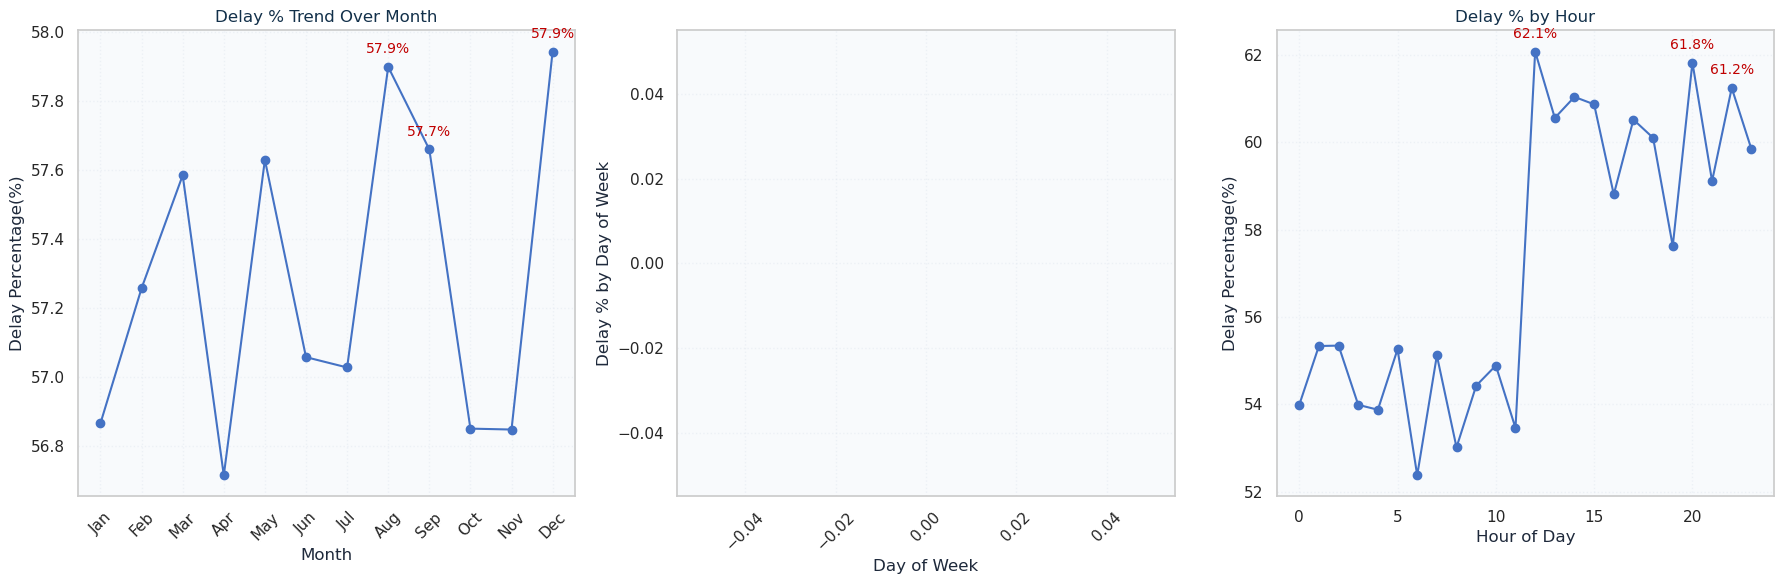

In [55]:
import matplotlib.pyplot as plt
import pandas as pd

# Define professional chart colors
primary_color = '#4472C4'  # Professional blue
danger_color = '#C00000'   # Dark red for highlighting
fig,(ax1,ax2,ax3)=plt.subplots(1,3,figsize=(18,6))

# Subplot 1:Delay % Trend over month
ax1.plot(delay_by_month['order_month'],delay_by_month['delay_pct'],marker='o',color=primary_color)
ax1.set_xticks(range(1,13))
ax1.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'],rotation=45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage(%)")
ax1.set_title("Delay % Trend Over Month")
ax1.grid(True,linestyle=':',alpha=0.5)

# Annotate top 3 highest 
top3_month=delay_by_month.nlargest(3,'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%",(row['order_month'],row['delay_pct']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10,color=danger_color)


# Subplot 2: Delay % by Day of week
day_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
delay_by_day['order_day']=pd.Categorical(delay_by_day['order_day'],categories=day_order, ordered=True)
delay_by_day=delay_by_day.sort_values('order_day')

ax2.bar(delay_by_day['order_day'],delay_by_day['delay_pct'],color=primary_color)
ax2.tick_params(axis='x',rotation=45)
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay % by Day of Week")
ax2.grid(True,linestyle=':',alpha=0.5)

#Annotate top 3 highest bars
top3_day=delay_by_day.nlargest(3,'delay_pct')
for _,row in top3_day.iterrows():
     height=row['delay_pct']
     ax2.text(row['order_day'],height+0.5,f'{height:.1f}%', ha='center', fontsize=10,color=danger_color)

# Subplot 3: delay percentage by hour
ax3.plot(delay_by_hour['order_hour'],delay_by_hour['delay_pct'],marker='o',color=primary_color)
ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage(%)")
ax3.set_title("Delay % by Hour")
ax3.grid(True,linestyle=':',alpha=0.5)


#Annotate top 3 highest bars
top3_hour=delay_by_hour.nlargest(3,'delay_pct')
for _,row in top3_hour.iterrows():
     ax3.annotate(f"{row['delay_pct']:.1f}%",(row['order_hour'],row['delay_pct']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10,color=danger_color)


plt.tight_layout()
plt.show()
    

In [59]:
# Convert order date to datetime
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'],
    errors='coerce'
)

# Extract day of week
df['order_day'] = df['order date (DateOrders)'].dt.day_name()

In [60]:
delay_by_day = (
    df.groupby('order_day')['Is_Delayed']
    .mean()
    .mul(100)
    .reset_index(name='delay_pct')
)

In [63]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

delay_by_day['order_day'] = pd.Categorical(
    delay_by_day['order_day'],
    categories=day_order,
    ordered=True
)

delay_by_day = delay_by_day.sort_values('order_day')

print(delay_by_day)

   order_day  delay_pct
1     Monday  57.930660
5    Tuesday  56.603700
6  Wednesday  57.189198
4   Thursday  57.238273
0     Friday  57.527483
2   Saturday  56.939886
3     Sunday  57.519464


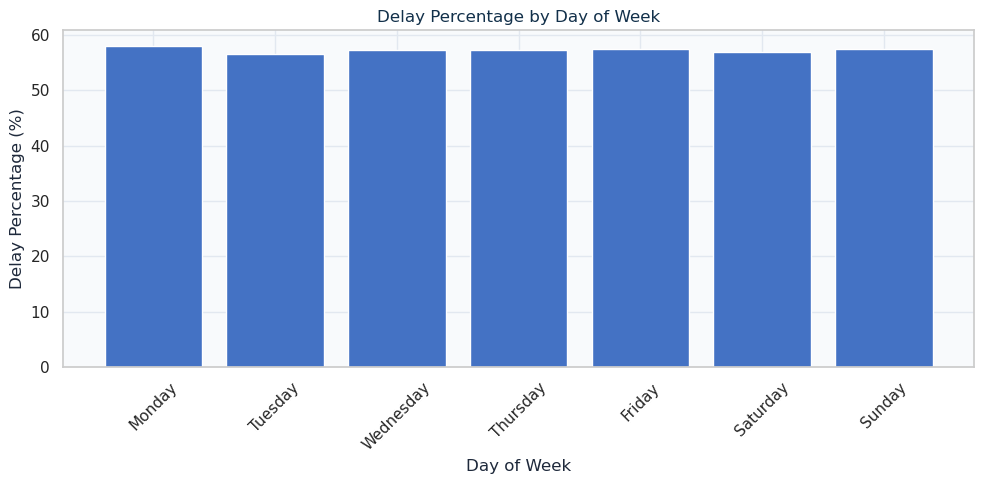

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    delay_by_day['order_day'].astype(str),
    delay_by_day['delay_pct'],
    color='#4472C4'
)

plt.xlabel("Day of Week")
plt.ylabel("Delay Percentage (%)")
plt.title("Delay Percentage by Day of Week")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [68]:
# Machine Learning Modeling

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE 

In [71]:
print(df.columns.tolist())


['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrde

In [72]:
# Independent variables (features)
X = df[[
    'Type',
    'Days for shipment (scheduled)',
    'Category Name',
    'Customer Segment',
    'Department Name',
    'Order Region',
    'Shipping Mode',
    'order_month',
    'order_hour'
]]

# Dependent variable (target)
y = df['Late_delivery_risk']

In [73]:

# Identify categorical columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print('Categorical columns:', cat_cols)

# Frequency encoding (low-dimensional and robust for high-cardinality)
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X[f'{col}_freq'] = X[col].map(freq)

# Keep numeric columns + new encoded features, drop original string categories
X_encoded = X.drop(columns=cat_cols)
print('Shape after freq+target encoding:', X_encoded.shape)

# Use encoded features for modeling
X = X_encoded

# Train/test split after encoding
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']
Shape after freq+target encoding: (180519, 9)


In [74]:
y.value_counts()

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

In [78]:
#Balancing the training data using SMOTE
print("Before balancing(train):",Counter(y_train))

smote=SMOTE(random_state=42)
X_train_bal,y_train_bal=smote.fit_resample(X_train,y_train)

print("After balancing(train):",Counter(y_train_bal))

Before balancing(train): Counter({1: 79181, 0: 65234})
After balancing(train): Counter({1: 79181, 0: 79181})


In [81]:

# Evaluate model
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 2))
    print("Precision:", round(precision_score(y_true, y_pred), 2))
    print("Recall:", round(recall_score(y_true, y_pred), 2))
    print("\nClassification Report:\n", classification_report(y_true, y_pred))


In [87]:
# Train Random Forest model
print("Training Random Forest model...")

rf_model_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model_balanced.fit(X_train_bal, y_train_bal)

print("Training completed!")

# Make predictions
y_pred_rf_balanced = rf_model_balanced.predict(X_test)

print("Predictions completed!")

# Evaluate the model
evaluate_model(
    y_test,
    y_pred_rf_balanced,
    "Random Forest Classifier"
)

Training Random Forest model...
Training completed!
Predictions completed!

--- Random Forest Classifier ---
Accuracy: 0.73
Precision: 0.77
Recall: 0.74

Classification Report:
               precision    recall  f1-score   support

           0       0.70      0.73      0.71     16308
           1       0.77      0.74      0.75     19796

    accuracy                           0.73     36104
   macro avg       0.73      0.73      0.73     36104
weighted avg       0.74      0.73      0.73     36104

